# Task 02 – House Rent Prediction (Regression)

**Problem statement:** predict the **monthly rent** of a house / flat in India from its size, rooms, floor, city and furnishing,
so tenants and owners can check if a rent is fair.

**Task type:** supervised **regression** – target `Rent` (Indian Rupees per month).

**Dataset:** [Kaggle – House Rent Prediction Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/house-rent-prediction-dataset) – 4,746 listings, 11 features + target.

| Column | Meaning |
|---|---|
| Posted On | date of the listing |
| BHK | number of Bedrooms, Hall, Kitchen |
| **Rent** | **target** – monthly rent (INR) |
| Size | size in square feet |
| Floor | e.g. `Ground out of 2`, `3 out of 5` |
| Area Type | Super Area / Carpet Area / Built Area |
| Area Locality | neighbourhood name |
| City | Mumbai, Chennai, Bangalore, Hyderabad, Delhi, Kolkata |
| Furnishing Status | Furnished / Semi-Furnished / Unfurnished |
| Tenant Preferred | Bachelors / Family / Bachelors/Family |
| Bathroom | number of bathrooms |
| Point of Contact | Contact Owner / Agent / Builder |

**Metrics:** R² (main), MAE, MSE, RMSE – models compared with **5-fold cross-validation on the training data**, the test set is used once at the end.

# Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings('ignore')
os.environ['PYTHONWARNINGS'] = 'ignore'   # also hide warnings inside the parallel workers (n_jobs=-1)
%matplotlib inline
sns.set_theme(style='whitegrid')

# Read data

In [2]:
df = pd.read_csv('dataset/House_Rent_Dataset.csv')
df.head()

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,5/18/2022,2,10000.0,1100.0,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2.0,Contact Owner
1,5/13/2022,2,20000.0,NaN,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
2,5/16/2022,2,17000.0,1000.0,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1.0,Contact Owner
3,7/4/2022,2,10000.0,NaN,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1.0,Contact Owner
4,5/9/2022,2,7500.0,850.0,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1.0,Contact Owner


In [3]:
df.shape

(4746, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Posted On          4746 non-null   object 
 1   BHK                4746 non-null   int64  
 2   Rent               4741 non-null   float64
 3   Size               4738 non-null   float64
 4   Floor              4746 non-null   object 
 5   Area Type          4739 non-null   object 
 6   Area Locality      4746 non-null   object 
 7   City               4746 non-null   object 
 8   Furnishing Status  4746 non-null   object 
 9   Tenant Preferred   4746 non-null   object 
 10  Bathroom           4742 non-null   float64
 11  Point of Contact   4746 non-null   object 
dtypes: float64(3), int64(1), object(8)
memory usage: 445.1+ KB


In [5]:
df.describe()

,BHK,Rent,Size,Bathroom
count,4746.000000,4.741000e+03,4738.000000,4742.000000
mean,2.083860,3.502340e+04,967.936049,1.965837
std,0.832256,7.814214e+04,634.562635,0.884904
min,1.000000,1.200000e+03,10.000000,1.000000
25%,2.000000,1.000000e+04,550.000000,1.000000
50%,2.000000,1.600000e+04,850.000000,2.000000
75%,3.000000,3.300000e+04,1200.000000,2.000000
max,6.000000,3.500000e+06,8000.000000,10.000000


# Data Understanding

In [6]:
for col in ['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']:
    print(df[col].value_counts().to_dict())
print('Area Locality unique values:', df['Area Locality'].nunique())
print('Floor unique values        :', df['Floor'].nunique(), df['Floor'].unique()[:6])
print('Posted On months           :', pd.to_datetime(df['Posted On']).dt.month.value_counts().sort_index().to_dict())

{'Super Area': 2442, 'Carpet Area': 2295, 'Built Area': 2}
{'Mumbai': 972, 'Chennai': 891, 'Bangalore': 886, 'Hyderabad': 868, 'Delhi': 605, 'Kolkata': 524}
{'Semi-Furnished': 2251, 'Unfurnished': 1815, 'Furnished': 680}
{'Bachelors/Family': 3444, 'Bachelors': 830, 'Family': 472}
{'Contact Owner': 3216, 'Contact Agent': 1529, 'Contact Builder': 1}
Area Locality unique values: 2235
Floor unique values        : 480 ['Ground out of 2' '1 out of 3' '1 out of 2' 'Ground out of 1'
 'Ground out of 4' '1 out of 4']
Posted On months           : {4: 228, 5: 1681, 6: 1859, 7: 978}


- `Floor` is text like `1 out of 3` → it holds **two numbers** (the floor and the total floors of the building).
- `Area Locality` has 2,235 different values for 4,746 rows → almost every row is unique.
- `Posted On` covers only April – July 2022.

# Data Cleaning

In [7]:
df.isnull().sum()

Posted On            0
BHK                  0
Rent                 5
Size                 8
Floor                0
Area Type            7
Area Locality        0
City                 0
Furnishing Status    0
Tenant Preferred     0
Bathroom             4
Point of Contact     0
dtype: int64

- `Rent` is the **target** → rows without a rent are dropped.
- Missing values in the features (Size, Area Type, Bathroom) are filled **inside the Pipeline** from the training data only.

In [8]:
df.dropna(subset=['Rent'], inplace=True)
print('Number of duplicate rows : ', df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)
df.shape

Number of duplicate rows :  0


(4741, 12)

# EDA & Statistical Analysis

Rent skewness     : 21.4
log(Rent) skewness: 0.91


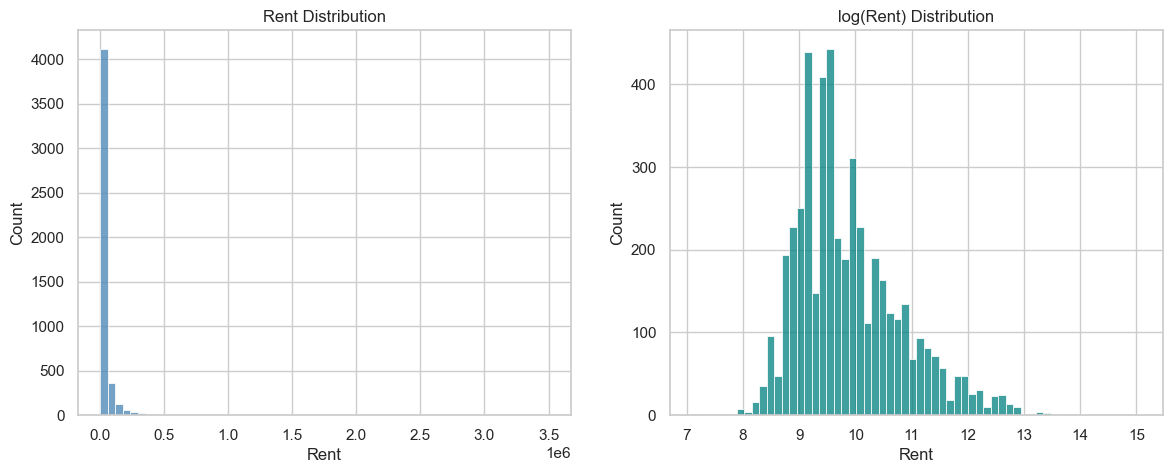

In [9]:
print('Rent skewness     :', round(df['Rent'].skew(), 2))
print('log(Rent) skewness:', round(np.log1p(df['Rent']).skew(), 2))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['Rent'], bins=60, color='steelblue', ax=ax[0])
ax[0].set_title('Rent Distribution')
sns.histplot(np.log1p(df['Rent']), bins=60, color='teal', ax=ax[1])
ax[1].set_title('log(Rent) Distribution')
plt.show()

The rent is **very right-skewed** → the models predict **log(Rent)**, and the prediction is converted back with `np.expm1`.

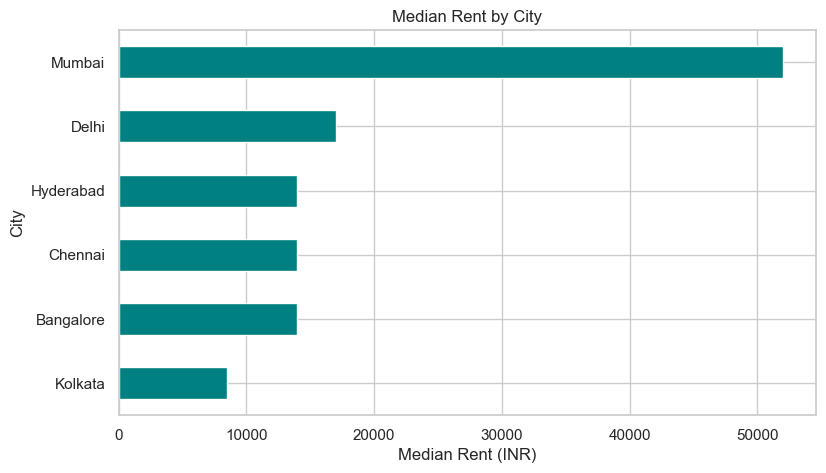

In [10]:
plt.figure(figsize=(9, 5))
df.groupby('City')['Rent'].median().sort_values().plot(kind='barh', color='teal')
plt.title('Median Rent by City')
plt.xlabel('Median Rent (INR)')
plt.show()

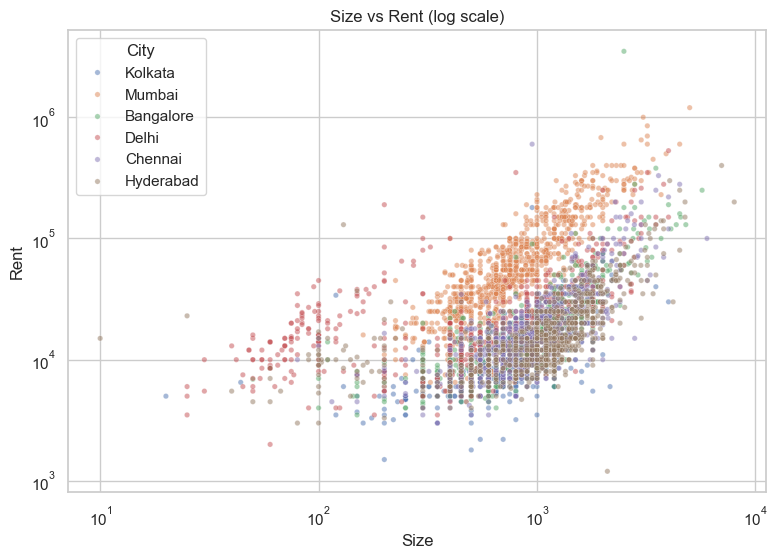

In [11]:
plt.figure(figsize=(9, 6))
sns.scatterplot(x='Size', y='Rent', hue='City', data=df, alpha=0.5, s=15)
plt.xscale('log')
plt.yscale('log')
plt.title('Size vs Rent (log scale)')
plt.show()

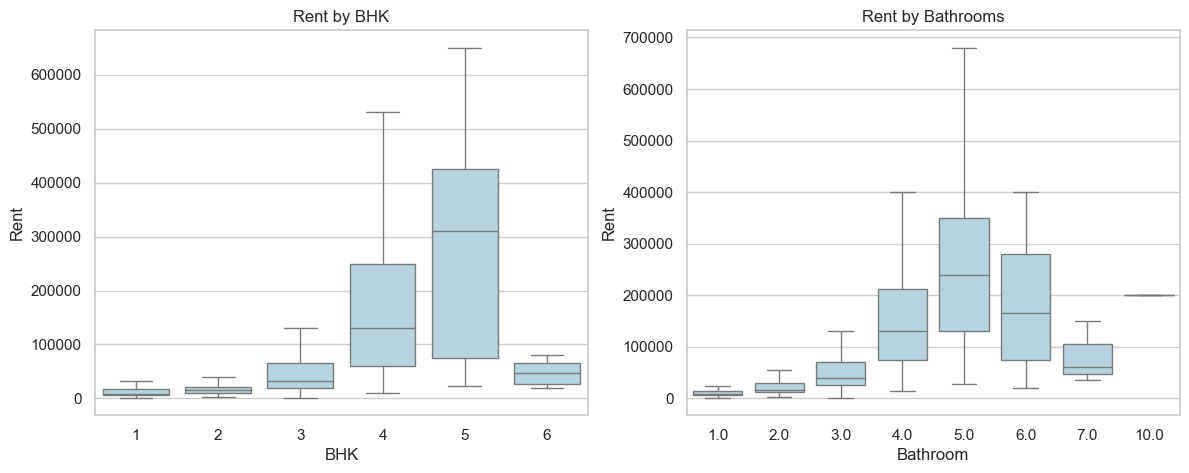

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(x='BHK', y='Rent', data=df, color='lightblue', showfliers=False, ax=ax[0])
ax[0].set_title('Rent by BHK')
sns.boxplot(x='Bathroom', y='Rent', data=df, color='lightblue', showfliers=False, ax=ax[1])
ax[1].set_title('Rent by Bathrooms')
plt.show()

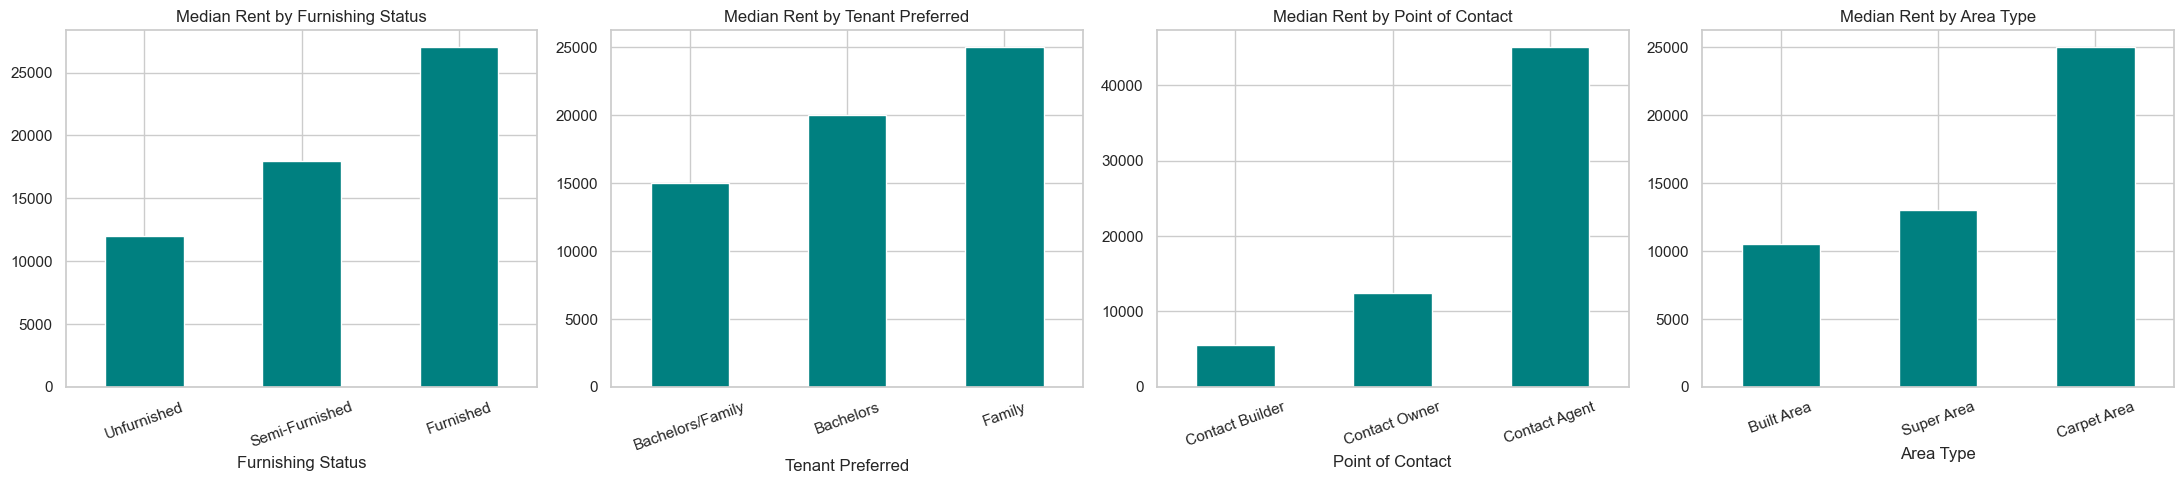

In [13]:
fig, ax = plt.subplots(1, 4, figsize=(22, 5))
for i, col in enumerate(['Furnishing Status', 'Tenant Preferred', 'Point of Contact', 'Area Type']):
    df.groupby(col)['Rent'].median().sort_values().plot(kind='bar', color='teal', ax=ax[i])
    ax[i].set_title('Median Rent by ' + col)
    ax[i].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

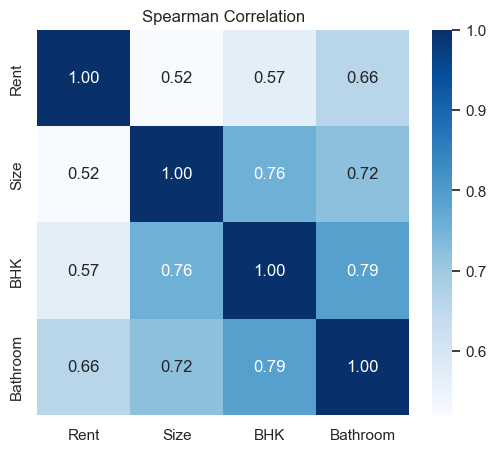

In [14]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[['Rent', 'Size', 'BHK', 'Bathroom']].corr(method='spearman'), annot=True, cmap='Blues', fmt='.2f')
plt.title('Spearman Correlation')
plt.show()

In [15]:
from scipy.stats import f_oneway

print('ANOVA: is the mean log(Rent) different between the groups?')
for col in ['City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact', 'Area Type']:
    groups = [np.log1p(g['Rent']) for _, g in df.groupby(col) if len(g) > 2]
    print(f'  {col:18s} p-value = {f_oneway(*groups).pvalue:.4g}')

ANOVA: is the mean log(Rent) different between the groups?
  City               p-value = 0
  Furnishing Status  p-value = 6.257e-89
  Tenant Preferred   p-value = 1.047e-34
  Point of Contact   p-value = 0
  Area Type          p-value = 2.478e-167


**EDA findings**
- **Target:** rent is extremely right-skewed (skewness 21.4, max 3.5M INR); log(Rent) has skewness 0.9 → the models predict log(Rent).
- **City is the biggest factor:** median rent in Mumbai is 52,000 INR vs 8,500 in Kolkata (6× difference); the other cities are 14,000 – 17,000.
- **Size & rooms:** rent grows with size (almost a straight line on the log-log plot) and with BHK / bathrooms (1 BHK 9,000 → 3 BHK 32,000 median).
- **Furnishing:** Furnished 27,000 > Semi-Furnished 18,000 > Unfurnished 12,000.
- **Point of Contact:** flats listed by an **agent** have a much higher median (45,000) than flats listed by the owner (12,500) – agents handle the expensive flats.
- **ANOVA:** City, Furnishing, Tenant Preferred, Point of Contact and Area Type all have p < 0.001 → all significant.

# Feature Engineering

In [16]:
def floor_number(text):
    floor = str(text).split(' out of ')[0]
    if floor == 'Ground':
        return 0
    if floor == 'Upper Basement':
        return -1
    if floor == 'Lower Basement':
        return -2
    return pd.to_numeric(floor, errors='coerce')

def total_floors(text):
    parts = str(text).split(' out of ')
    return pd.to_numeric(parts[1], errors='coerce') if len(parts) == 2 else np.nan

df['Floor_Num'] = df['Floor'].apply(floor_number)
df['Total_Floors'] = df['Floor'].apply(total_floors)
df['Log_Size'] = np.log1p(df['Size'])          # rent grows with size in a log-log way
df['Size_per_BHK'] = df['Size'] / df['BHK']    # bigger rooms -> more expensive

df[['Floor', 'Floor_Num', 'Total_Floors', 'Size', 'Log_Size', 'Size_per_BHK']].head()

,Floor,Floor_Num,Total_Floors,Size,Log_Size,Size_per_BHK
0,Ground out of 2,0,2.0,1100.0,7.003974,550.0
1,1 out of 3,1,3.0,NaN,NaN,NaN
2,1 out of 3,1,3.0,1000.0,6.908755,500.0
3,1 out of 2,1,2.0,NaN,NaN,NaN
4,1 out of 2,1,2.0,850.0,6.746412,425.0


In [17]:
df[['Floor_Num', 'Total_Floors', 'Log_Size', 'Size_per_BHK']].corrwith(np.log1p(df['Rent']), method='spearman')

Floor_Num       0.482561
Total_Floors    0.581438
Log_Size        0.520588
Size_per_BHK    0.195151
dtype: float64

- `Total_Floors` has a clear relation with the rent (tall buildings = modern apartments in big cities).
- All new features are row-by-row formulas → **no data leakage**.
- `Rent per sqft` is **not** used as a feature because it contains the target.

# Feature Selection

- **Dropped `Area Locality`:** 2,235 values for 4,746 rows – most appear only once, so the model can't learn from them (and `City` already gives the location).
- **Dropped `Posted On`:** all listings are from 4 months of 2022 – too short to show a time trend.
- **Dropped `Floor`:** replaced by the two numbers `Floor_Num` and `Total_Floors`.
- All the other features showed a clear difference in the EDA / ANOVA (p < 0.05) and are kept.

In [18]:
num_cols = ['BHK', 'Size', 'Log_Size', 'Size_per_BHK', 'Bathroom', 'Floor_Num', 'Total_Floors']
cat_cols = ['Area Type', 'City', 'Furnishing Status', 'Tenant Preferred', 'Point of Contact']

# Split data

In [19]:
from sklearn.model_selection import train_test_split

X = df[num_cols + cat_cols]
y = np.log1p(df['Rent'])   # log target

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)
print('X_train = ', X_train.shape, ' y_train = ', y_train.shape)
print('X_test  = ', X_test.shape, ' y_test  = ', y_test.shape)

X_train =  (3792, 12)  y_train =  (3792,)
X_test  =  (949, 12)  y_test  =  (949,)


# Outliers (IQR limits from the training data only)

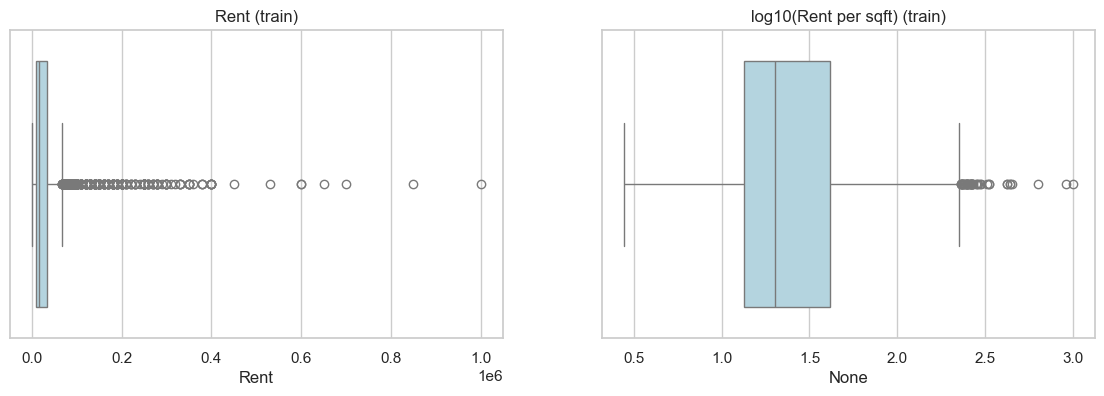

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=np.expm1(y_train), color='lightblue', ax=ax[0])
ax[0].set_title('Rent (train)')
sns.boxplot(x=np.log10(np.expm1(y_train) / X_train['Size']), color='lightblue', ax=ax[1])
ax[1].set_title('log10(Rent per sqft) (train)')
plt.show()

A very expensive flat in Mumbai is real, so the outliers are judged by **rent per sqft** (log scale) with the **IQR rule**.
The limits are learned from the **training data only**, then the same rule is applied to the test set.

In [21]:
train_rps = np.log(np.expm1(y_train) / X_train['Size'])   # log(rent per sqft)
q1 = train_rps.quantile(0.25)
q3 = train_rps.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print('Accepted rent per sqft :', round(np.exp(lower), 1), 'to', round(np.exp(upper), 1), 'INR')

def remove_outliers(X_part, y_part):
    rps = np.log(np.expm1(y_part) / X_part['Size'])
    keep = rps.isna() | ((rps >= lower) & (rps <= upper))   # rows without Size are kept
    print('removed rows :', (~keep).sum())
    return X_part[keep], y_part[keep]

X_train, y_train = remove_outliers(X_train, y_train)
X_test, y_test = remove_outliers(X_test, y_test)
print('X_train = ', X_train.shape, ' X_test = ', X_test.shape)

Accepted rent per sqft : 2.4 to 229.3 INR
removed rows : 43
removed rows : 19
X_train =  (3749, 12)  X_test =  (930, 12)


# Preprocessing (Pipeline + ColumnTransformer)

In [22]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='infrequent_if_exist', min_frequency=5))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])

- **Imputation:** median for numbers, most frequent value for categories.
- **Scaling:** `StandardScaler` – needed by KNN, SVR and the regularized linear models.
- **Encoding:** `OneHotEncoder` (no order between cities etc.). Very rare values (e.g. `Built Area` with 2 rows, `Contact Builder` with 1 row) are grouped as *infrequent*.
  `drop='first'` removes one column per feature to avoid the **dummy variable trap** (the dummy columns of one feature always add up to 1, which makes plain Linear Regression unstable:
  without it, one CV fold gave R² = −2×10²³ because the single `Contact Builder` row was only in the validation fold).
- Everything is inside a **Pipeline** → fitted on the training folds only → **no data leakage**.

# Models

| Model | Why it is tried |
|---|---|
| Linear Regression | simple baseline, easy to explain |
| Ridge / Lasso / ElasticNet | linear + regularization (L2 / L1 / both) |
| KNN Regressor | the rent of the most similar flats |
| Decision Tree | non-linear rules, easy to read, but overfits |
| Random Forest / Extra Trees | many trees averaged → less overfitting |
| SVR | non-linear (RBF kernel) on scaled data |
| Gradient Boosting / AdaBoost | boosting: each tree corrects the previous ones |
| XGBoost / LightGBM | fast, regularized gradient boosting |

**Excluded:** classification models (the target is a number). Polynomial Regression is not used because the tree / boosting models already learn the interactions.

In [23]:
from sklearn.model_selection import KFold, cross_validate, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

In [24]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=0.001),
    'ElasticNet': ElasticNet(alpha=0.001, l1_ratio=0.5),
    'KNN': KNeighborsRegressor(n_neighbors=5),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42),
    'SVR': SVR(kernel='rbf'),
    'Gradient Boosting': GradientBoostingRegressor(random_state=42),
    'AdaBoost': AdaBoostRegressor(random_state=42),
    'Extra Trees': ExtraTreesRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42),
    'LightGBM': LGBMRegressor(random_state=42, verbose=-1),
}

## Model comparison with 5-fold cross-validation (training data only, log rent)

In [25]:
kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error', 'MSE': 'neg_mean_squared_error', 'RMSE': 'neg_root_mean_squared_error'}

results = {}
for name, model in models.items():
    pipe = Pipeline([('preprocessor', preprocessor), ('model', model)])
    cv = cross_validate(pipe, X_train, y_train, cv=kfold, scoring=scoring, return_train_score=True, n_jobs=-1)
    results[name] = {
        'Train R2': cv['train_R2'].mean(),
        'CV R2': cv['test_R2'].mean(),
        'CV MAE': -cv['test_MAE'].mean(),
        'CV MSE': -cv['test_MSE'].mean(),
        'CV RMSE': -cv['test_RMSE'].mean(),
    }
    print(f"{name:18s}  CV R2 = {results[name]['CV R2']:.4f}")

Linear Regression   CV R2 = 0.8287


Ridge               CV R2 = 0.8287


Lasso               CV R2 = 0.8287
ElasticNet          CV R2 = 0.8287


KNN                 CV R2 = 0.8086
Decision Tree       CV R2 = 0.7000


Random Forest       CV R2 = 0.8289


SVR                 CV R2 = 0.8385


Gradient Boosting   CV R2 = 0.8399


AdaBoost            CV R2 = 0.7758


Extra Trees         CV R2 = 0.8130
XGBoost             CV R2 = 0.8302


LightGBM            CV R2 = 0.8411


In [26]:
comparison = pd.DataFrame(results).T.sort_values('CV R2', ascending=False)
comparison.round(4)

,Train R2,CV R2,CV MAE,CV MSE,CV RMSE
LightGBM,0.9117,0.8411,0.2784,0.1344,0.3665
Gradient Boosting,0.8695,0.8399,0.2799,0.1354,0.3679
SVR,0.8758,0.8385,0.2775,0.1365,0.3692
XGBoost,0.9599,0.8302,0.2878,0.1436,0.3789
Random Forest,0.9728,0.8289,0.2899,0.1449,0.3805
ElasticNet,0.8341,0.8287,0.2881,0.1448,0.3803
Lasso,0.8340,0.8287,0.2881,0.1449,0.3803
Ridge,0.8342,0.8287,0.2882,0.1449,0.3803
Linear Regression,0.8342,0.8287,0.2882,0.1449,0.3803
Extra Trees,0.9955,0.8130,0.3031,0.1583,0.3977


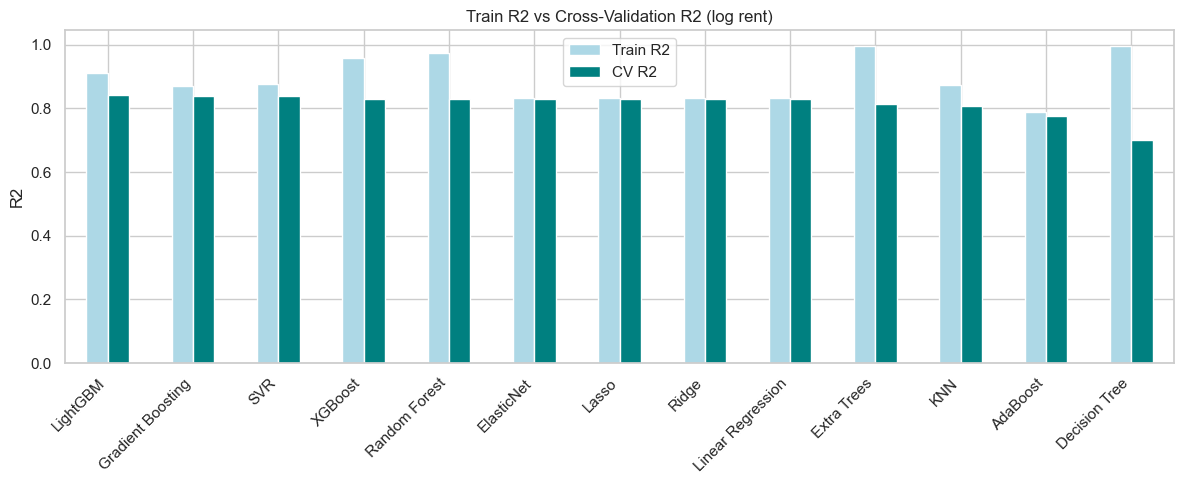

In [27]:
comparison[['Train R2', 'CV R2']].plot(kind='bar', figsize=(12, 5), color=['lightblue', 'teal'])
plt.title('Train R2 vs Cross-Validation R2 (log rent)')
plt.ylabel('R2')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Comparison results (5-fold CV on the training data, log rent)**
- **Best:** LightGBM (CV R² 0.841), Gradient Boosting (0.840), SVR (0.839) – very close to each other.
- **Linear models are almost as good** (Linear / Ridge / Lasso / ElasticNet ≈ 0.829): after the log transform and `Log_Size`, rent is close to a straight line,
  and train ≈ CV (0.834 vs 0.829) → no overfitting. Ridge = Linear Regression because there are only ~20 columns and enough rows.
- **Overfitting:** Decision Tree (train 0.996 → CV 0.700) and Extra Trees (0.996 → 0.813) memorize the training data. Random Forest and XGBoost also have a big gap (≈ 0.96 → 0.83).
- **AdaBoost** (0.776) and **KNN** (0.809) are weaker.
- The **top 3 (LightGBM, Gradient Boosting, SVR)** go to GridSearchCV.

# GridSearchCV (top 3 models)

A parameter grid is prepared for every model; the **top 3 models** from the comparison table are tuned with 5-fold cross-validation on the training data.

In [28]:
param_grids = {
    'Linear Regression': {'model__fit_intercept': [True, False]},
    'Ridge': {'model__alpha': [0.1, 1, 10, 100]},
    'Lasso': {'model__alpha': [0.0001, 0.001, 0.01]},
    'ElasticNet': {'model__alpha': [0.0001, 0.001, 0.01], 'model__l1_ratio': [0.2, 0.5, 0.8]},
    'KNN': {'model__n_neighbors': [5, 10, 20], 'model__weights': ['uniform', 'distance']},
    'Decision Tree': {'model__max_depth': [5, 10, None], 'model__min_samples_leaf': [1, 5, 10]},
    'Random Forest': {'model__n_estimators': [200, 400], 'model__max_features': [0.5, 1.0], 'model__min_samples_leaf': [1, 3]},
    'SVR': {'model__C': [1, 3, 10], 'model__gamma': ['scale', 0.05]},
    'Gradient Boosting': {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 4]},
    'AdaBoost': {'model__n_estimators': [50, 100], 'model__learning_rate': [0.1, 1.0]},
    'Extra Trees': {'model__n_estimators': [200, 400], 'model__max_features': [0.5, 1.0], 'model__min_samples_leaf': [1, 3]},
    'XGBoost': {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 5]},
    'LightGBM': {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__num_leaves': [15, 31]},
}

In [29]:
top_models = comparison.index[:3]
grids = {}

for name in top_models:
    pipe = Pipeline([('preprocessor', preprocessor), ('model', models[name])])
    grid = GridSearchCV(pipe, param_grids[name], cv=kfold, scoring='r2', n_jobs=-1)
    grid.fit(X_train, y_train)
    grids[name] = grid

    print('=' * 60)
    print(name)
    print('Parameter grid :', param_grids[name])
    print('best_params_   :', grid.best_params_)
    print('best_score_    :', round(grid.best_score_, 4), '(CV R2)')

LightGBM
Parameter grid : {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__num_leaves': [15, 31]}
best_params_   : {'model__learning_rate': 0.05, 'model__n_estimators': 200, 'model__num_leaves': 15}
best_score_    : 0.8436 (CV R2)


Gradient Boosting
Parameter grid : {'model__n_estimators': [200, 400], 'model__learning_rate': [0.05, 0.1], 'model__max_depth': [3, 4]}
best_params_   : {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 400}
best_score_    : 0.8454 (CV R2)


SVR
Parameter grid : {'model__C': [1, 3, 10], 'model__gamma': ['scale', 0.05]}
best_params_   : {'model__C': 3, 'model__gamma': 0.05}
best_score_    : 0.8419 (CV R2)


## Before vs after tuning (cross-validation R2)

In [30]:
tuning = pd.DataFrame({
    'CV R2 before tuning': comparison.loc[top_models, 'CV R2'],
    'CV R2 after tuning': [grids[name].best_score_ for name in top_models],
})
tuning['Improvement'] = tuning['CV R2 after tuning'] - tuning['CV R2 before tuning']
tuning['Best params'] = [grids[name].best_params_ for name in top_models]
tuning = tuning.sort_values('CV R2 after tuning', ascending=False)
tuning

,CV R2 before tuning,CV R2 after tuning,Improvement,Best params
Gradient Boosting,0.839921,0.845383,0.005462,"{'model__learning_rate': 0.05, 'model__max_dep..."
LightGBM,0.841054,0.843604,0.002550,"{'model__learning_rate': 0.05, 'model__n_estim..."
SVR,0.838490,0.841853,0.003363,"{'model__C': 3, 'model__gamma': 0.05}"


In [31]:
best_name = tuning.index[0]   # chosen by the cross-validation score, not by the test set
best_model = grids[best_name].best_estimator_
print('Best model :', best_name)
print('Best params:', grids[best_name].best_params_)

Best model : Gradient Boosting
Best params: {'model__learning_rate': 0.05, 'model__max_depth': 4, 'model__n_estimators': 400}


# Final Evaluation on the Test Set

In [32]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE': mean_absolute_error(y_true, y_pred), 'MSE': mse, 'RMSE': np.sqrt(mse), 'R2': r2_score(y_true, y_pred)}

base_model = Pipeline([('preprocessor', preprocessor), ('model', models[best_name])]).fit(X_train, y_train)   # before tuning

y_pred_base = base_model.predict(X_test)
y_pred = best_model.predict(X_test)
y_test_inr = np.expm1(y_test)
y_pred_inr = np.expm1(y_pred)

final = pd.DataFrame({
    'Before tuning (log)': regression_metrics(y_test, y_pred_base),
    'After tuning (log)': regression_metrics(y_test, y_pred),
    'Before tuning (INR)': regression_metrics(y_test_inr, np.expm1(y_pred_base)),
    'After tuning (INR)': regression_metrics(y_test_inr, y_pred_inr),
}).T
final.style.format('{:,.4f}')

,MAE,MSE,RMSE,R2
Before tuning (log),0.2788,0.1463,0.3825,0.8294
After tuning (log),0.2766,0.1461,0.3823,0.8295
Before tuning (INR),"9,597.9802","541,515,868.7587","23,270.4935",0.8100
After tuning (INR),"9,756.8908","587,351,768.8400","24,235.3413",0.7939


In [33]:
ape = np.abs(y_pred_inr - y_test_inr) / y_test_inr * 100   # absolute percentage error
print('Median error           :', round(np.median(ape), 1), '%')
print('Predictions within 20% :', round((ape <= 20).mean() * 100, 1), '%')
print('Predictions within 50% :', round((ape <= 50).mean() * 100, 1), '%')

Median error           : 21.6 %
Predictions within 20% : 46.8 %
Predictions within 50% : 86.9 %


## Actual vs Predicted

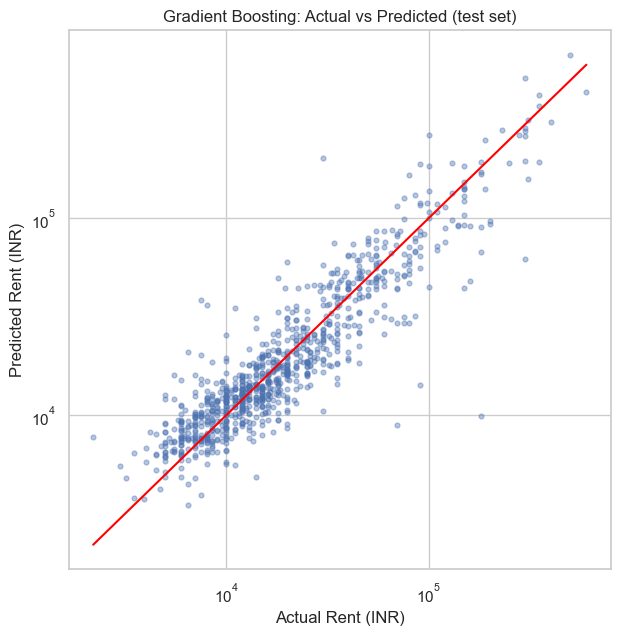

In [34]:
plt.figure(figsize=(7, 7))
plt.scatter(y_test_inr, y_pred_inr, alpha=0.4, s=12)
lim = [y_test_inr.min(), y_test_inr.max()]
plt.plot(lim, lim, color='red')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Actual Rent (INR)')
plt.ylabel('Predicted Rent (INR)')
plt.title(best_name + ': Actual vs Predicted (test set)')
plt.show()

## Residuals

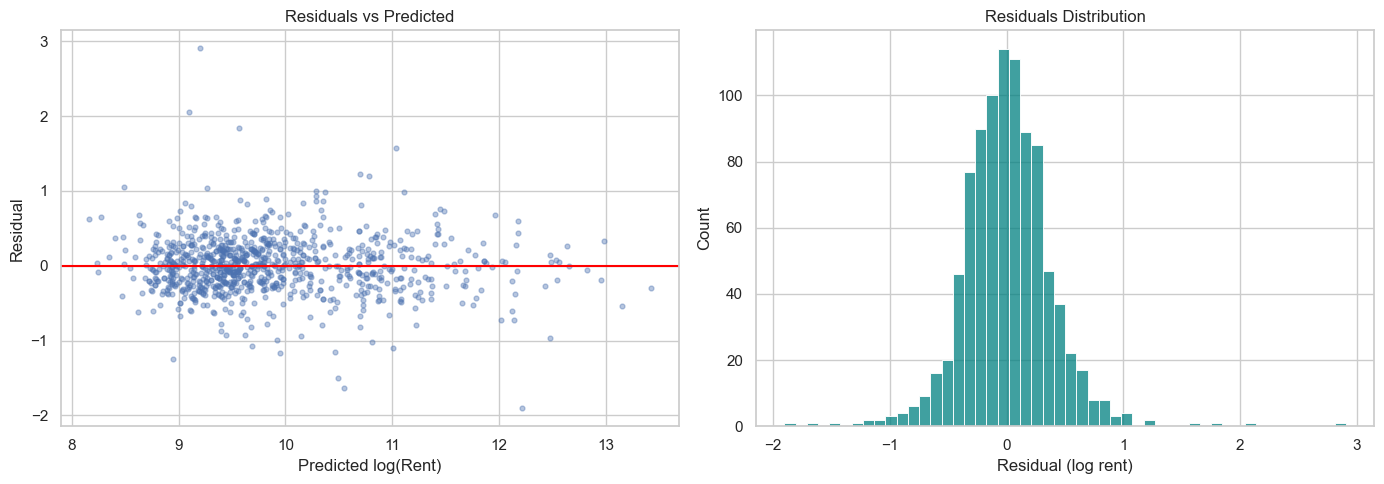

In [35]:
residuals = y_test - y_pred   # log scale

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_pred, residuals, alpha=0.4, s=12)
ax[0].axhline(0, color='red')
ax[0].set_xlabel('Predicted log(Rent)')
ax[0].set_ylabel('Residual')
ax[0].set_title('Residuals vs Predicted')
sns.histplot(residuals, bins=50, color='teal', ax=ax[1])
ax[1].set_xlabel('Residual (log rent)')
ax[1].set_title('Residuals Distribution')
plt.tight_layout()
plt.show()

## Error by city

In [36]:
errors = pd.DataFrame({'City': X_test['City'], 'APE %': ape})
errors.groupby('City')['APE %'].agg(['count', 'median']).sort_values('median').round(1)

,count,median
City,,
Bangalore,171,19.6
Kolkata,116,20.1
Delhi,103,20.4
Chennai,167,22.5
Hyderabad,184,23.0
Mumbai,189,24.0


## Which features matter? (permutation importance on the test set)

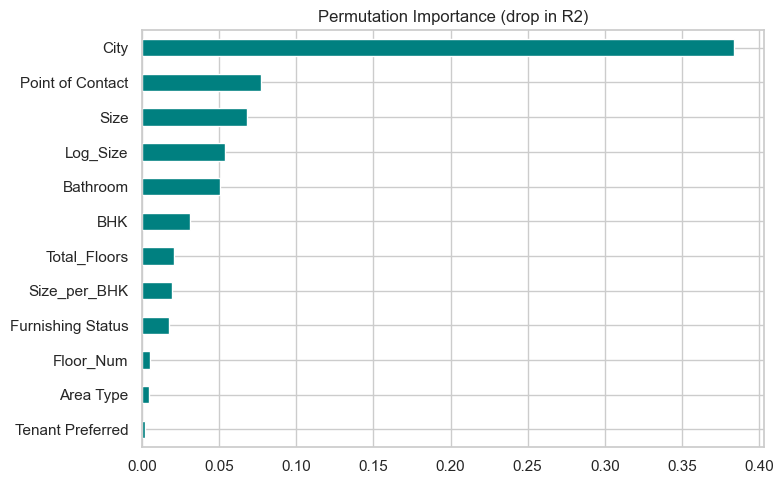

In [37]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(best_model, X_test, y_test, n_repeats=10, random_state=42, scoring='r2', n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

plt.figure(figsize=(8, 5))
importance.plot(kind='barh', color='teal')
plt.title('Permutation Importance (drop in R2)')
plt.tight_layout()
plt.show()

**Interpretation of errors & discussion of model performance**
- **GridSearchCV:** Gradient Boosting improved the most (CV R² 0.840 → **0.845**, learning_rate 0.05, max_depth 4, 400 trees) and became the best model;
  LightGBM 0.841 → 0.844, SVR 0.838 → 0.842. All three end within 0.004 of each other.
- **Test set:** R² **0.83** on log rent (CV said 0.845 → consistent), RMSE 0.38 (log), median error **≈ 22 %**, 47 % of predictions within ±20 % and 87 % within ±50 %.
- **Before vs after tuning on the test set:** the log-scale scores are almost the same (0.8294 → 0.8295), and in INR the R² even drops a little (0.810 → 0.794):
  tuning optimized the **log** error, while the INR metrics are dominated by a few very expensive Mumbai flats. The gain from tuning is small – the data, not the model settings, is the limit.
- **Actual vs Predicted:** the points follow the red line from ~5,000 to ~500,000 INR. The biggest misses are a few flats priced far above or below similar flats (e.g. luxury flats in normal areas).
- **Residuals:** centered at 0, bell-shaped, no pattern vs the predicted value → no systematic bias.
- **By city:** Bangalore is predicted best (19.6 % median error), Mumbai is hardest (24 %) because its rents vary the most between areas.
- **Most important features:** **City** by far, then Point of Contact, Size / Log_Size, Bathroom and BHK. Tenant Preferred and Area Type matter least.
- **Limits:** the exact location (`Area Locality`) had to be dropped (too many unique values) – but location inside a city is a big part of the rent.

# Gradio App (deployment)
The final model is put into a small web app. The user describes the flat, the app builds the same engineered features as in the
Feature Engineering step (`Log_Size`, `Size_per_BHK`, `Floor_Num`, `Total_Floors`), the model predicts **log(rent)** and `np.expm1` turns it back into rupees.

- The tuned pipeline (`best_model`) is used directly, so the app gives exactly the same answers as the evaluation above.
- A **± 20 % range** is shown next to the prediction, because the median error on the test set is ≈ 22 % (see Recommendations).
- Run the cell below to open the app **inside the notebook** (or at the local link it prints).

In [38]:
import gradio as gr

def predict_rent(city, bhk, size, bathroom, floor_num, total_floors, area_type, furnishing, tenant, contact):
    flat = pd.DataFrame([{
        'BHK': bhk, 'Size': size, 'Bathroom': bathroom, 'Floor_Num': floor_num, 'Total_Floors': total_floors,
        'Area Type': area_type, 'City': city, 'Furnishing Status': furnishing,
        'Tenant Preferred': tenant, 'Point of Contact': contact,
    }])
    flat['Log_Size'] = np.log1p(flat['Size'])            # same feature engineering as above
    flat['Size_per_BHK'] = flat['Size'] / flat['BHK']

    rent = float(np.expm1(best_model.predict(flat[num_cols + cat_cols])[0]))   # the model predicts log(rent)
    return f'{rent:,.0f} INR / month', f'{rent * 0.8:,.0f} – {rent * 1.2:,.0f} INR'

demo = gr.Interface(
    fn=predict_rent,
    inputs=[
        gr.Dropdown(sorted(X_train['City'].unique()), value='Bangalore', label='City'),
        gr.Number(value=2, label='BHK (bedrooms)', precision=0),
        gr.Number(value=1000, label='Size (sqft)'),
        gr.Number(value=2, label='Bathrooms', precision=0),
        gr.Number(value=1, label='Floor (0 = ground)', precision=0),
        gr.Number(value=4, label='Total floors in the building', precision=0),
        gr.Dropdown(sorted(X_train['Area Type'].dropna().unique()), value='Super Area', label='Area Type'),
        gr.Dropdown(sorted(X_train['Furnishing Status'].unique()), value='Semi-Furnished', label='Furnishing Status'),
        gr.Dropdown(sorted(X_train['Tenant Preferred'].unique()), value='Bachelors/Family', label='Tenant Preferred'),
        gr.Dropdown(sorted(X_train['Point of Contact'].unique()), value='Contact Owner', label='Point of Contact'),
    ],
    outputs=[
        gr.Textbox(label='Predicted rent'),
        gr.Textbox(label='Fair range (± 20 %)'),
    ],
    examples=[
        ['Bangalore', 2, 1000, 2, 1, 4, 'Super Area', 'Semi-Furnished', 'Bachelors/Family', 'Contact Owner'],
        ['Mumbai', 2, 800, 2, 10, 20, 'Carpet Area', 'Furnished', 'Bachelors/Family', 'Contact Agent'],
        ['Kolkata', 1, 500, 1, 0, 2, 'Super Area', 'Unfurnished', 'Bachelors/Family', 'Contact Owner'],
    ],
    title='House Rent Prediction (India)',
    description='Describe the flat to get an estimated monthly rent (typical error ≈ 22 %).',
)

demo.launch()

Running on local URL:  http://127.0.0.1:7862

To create a public link, set `share=True` in `launch()`.


In [39]:
# quick check: the app function gives sensible answers
for f in [['Bangalore', 2, 1000, 2, 1, 4, 'Super Area', 'Semi-Furnished', 'Bachelors/Family', 'Contact Owner'],
          ['Mumbai', 2, 800, 2, 10, 20, 'Carpet Area', 'Furnished', 'Bachelors/Family', 'Contact Agent'],
          ['Kolkata', 1, 500, 1, 0, 2, 'Super Area', 'Unfurnished', 'Bachelors/Family', 'Contact Owner']]:
    print(f'{f[0]:10s} {f[1]} BHK {f[2]} sqft  ->', predict_rent(*f)[0])

Bangalore  2 BHK 1000 sqft  -> 15,233 INR / month
Mumbai     2 BHK 800 sqft  -> 67,242 INR / month
Kolkata    1 BHK 500 sqft  -> 5,345 INR / month


# Conclusions & Recommendations

**Conclusions**
1. After cleaning, parsing `Floor` into two numbers and removing rent-per-sqft outliers (IQR from training data only), 4,679 listings were used.
2. Rent is driven mainly by **city**, **size** (Size, BHK, bathrooms), **who lists it** (agent vs owner) and **furnishing**.
3. 13 regression models were compared with 5-fold CV. Boosting and SVR were the best, but linear models were very close because log(rent) is almost linear in log(size).
4. The final model, **Gradient Boosting (tuned)**, reaches **R² = 0.83 on the test set** (log rent) with a median error of about 22 %.

**Recommendations**
- Use the model for a **fair-rent range** (± 20 %), especially outside Mumbai.
- Add **location inside the city** (e.g. distance to the city center or grouped localities) – the biggest missing information.
- Keep `drop='first'` in the one-hot encoder (or use regularized models) to avoid the dummy variable trap with plain Linear Regression.